In [1]:
import sys
sys.path.append("..")
import glob, json
import cv2
import numpy as np
import pandas as pd
from tensorflow import keras
from sklearn.metrics import f1_score
from src.preprocess import preprocess_image

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letter_to_idx = {v: k for k, v in idx_to_letter.items()}

# 1. Charger les photos
paths = []
for ext in ("jpg", "jpeg", "JPG", "JPEG", "png", "PNG"):
    paths += glob.glob(f"../data/real/*/*/*.{ext}")
paths = sorted(set(paths))

rows, X = [], []
for path in paths:
    parts = path.replace("\\", "/").split("/")
    person, letter = parts[-3], parts[-2].upper()
    if letter not in letter_to_idx:
        continue
    img = cv2.imread(path)
    if img is None:
        continue
    X.append(preprocess_image(img))
    rows.append({"person": person, "letter": letter,
                 "y": letter_to_idx[letter], "path": path})

X = np.array(X)
df = pd.DataFrame(rows)
print(len(df), "photos chargées")
print(df.groupby("person").size())

# 2. Comparer les modèles
models = {
    "CNN amélioré": keras.models.load_model("../data/cnn_final.keras"),
    "CNN robuste": keras.models.load_model("../data/cnn_robuste.keras"),
}

res = []
for name, m in models.items():
    pred = m.predict(X, verbose=0).argmax(1)
    p = m.predict(X, verbose=0)
    df[f"ok_{name}"] = pred == df["y"].values
    res.append({
        "Modèle": name,
        "Accuracy photos": round(float(df[f"ok_{name}"].mean()), 3),
        "F1 macro": round(float(f1_score(df["y"], pred, average="macro")), 3),
        "Confiance moyenne": round(float(p.max(1).mean()), 3),
    })

print(pd.DataFrame(res).to_string(index=False))
for name in models:
    print("\n" + name)
    print(df.groupby("person")[f"ok_{name}"].agg(["mean", "count"]).round(3))

152 photos chargées
person
malak    110
sara      18
zineb     24
dtype: int64
      Modèle  Accuracy photos  F1 macro  Confiance moyenne
CNN amélioré            0.362     0.348              0.811
 CNN robuste            0.336     0.315              0.753

CNN amélioré
         mean  count
person              
malak   0.436    110
sara    0.222     18
zineb   0.125     24

CNN robuste
         mean  count
person              
malak   0.418    110
sara    0.167     18
zineb   0.083     24


In [11]:
import cv2

from src.preprocess import crop_hand
n_ok = sum(crop_hand_ok is not None for crop_hand_ok in
           [__import__("src.preprocess", fromlist=["crop_hand"]).crop_hand(cv2.imread(p)) for p in df["path"]])
print(f"Main détectée sur {n_ok} photos sur {len(df)}")

df["main_detectee"] = [crop_hand(cv2.imread(p)) is not None for p in df["path"]]
print(df[~df["main_detectee"]][["person", "letter", "path"]])


Main détectée sur 150 photos sur 152
    person letter                                               path
12   malak      C  ../data/real\malak\C\WhatsApp Image 2026-11-14...
134  zineb      G  ../data/real\zineb\G\a29cd7b6-e79c-4cf4-9670-d...


In [12]:
name = "CNN amélioré"
pred = models[name].predict(X, verbose=0).argmax(1)
df["pred"] = pd.Series(pred).map(idx_to_letter)
err = df[df["pred"] != df["letter"]]
print(err.groupby(["letter", "pred"]).size().sort_values(ascending=False).head(15))

letter  pred
G       P       6
H       P       5
X       P       5
T       G       4
M       A       3
L       P       3
E       P       3
C       P       3
R       K       3
F       W       2
I       Y       2
        P       2
R       U       2
Q       P       2
S       F       2
dtype: int64


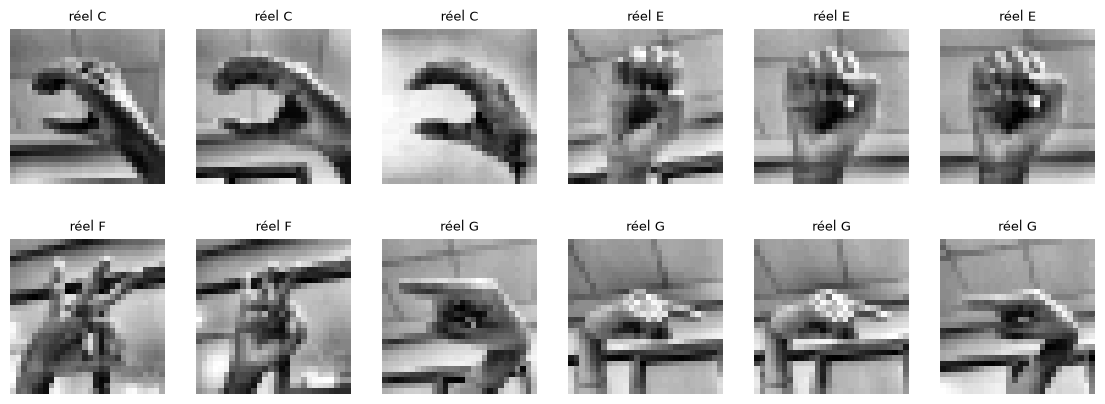

In [9]:
wrong_p = df[(df["pred"] == "P") & (df["letter"] != "P")].head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, (i, r) in zip(axes.ravel(), wrong_p.iterrows()):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(f"réel {r['letter']}", fontsize=9)
plt.show()

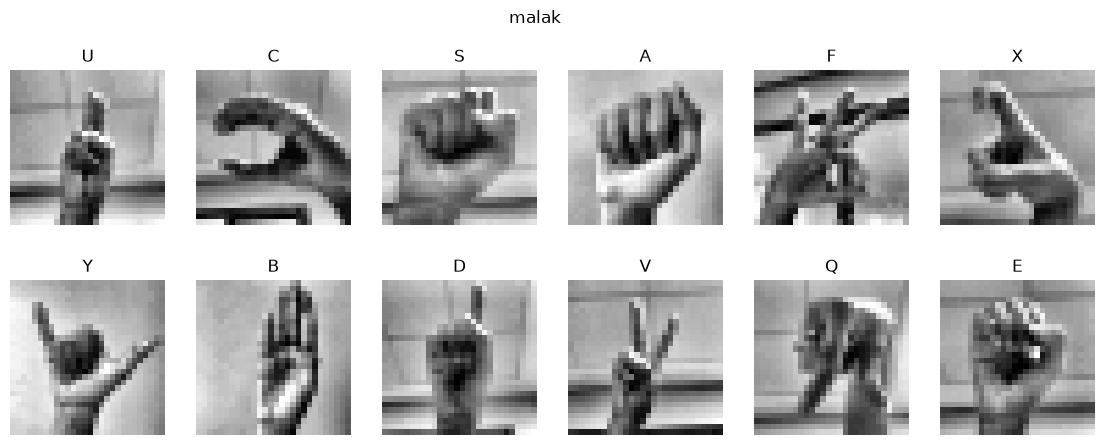

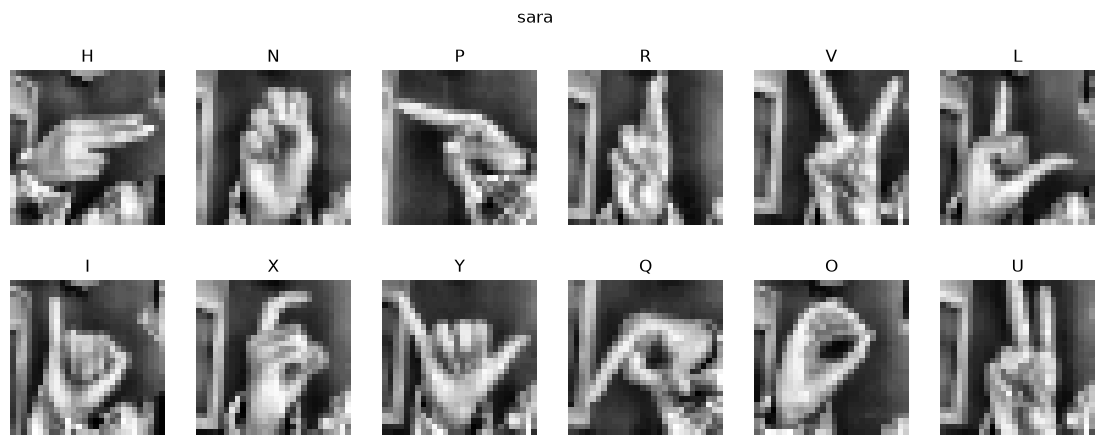

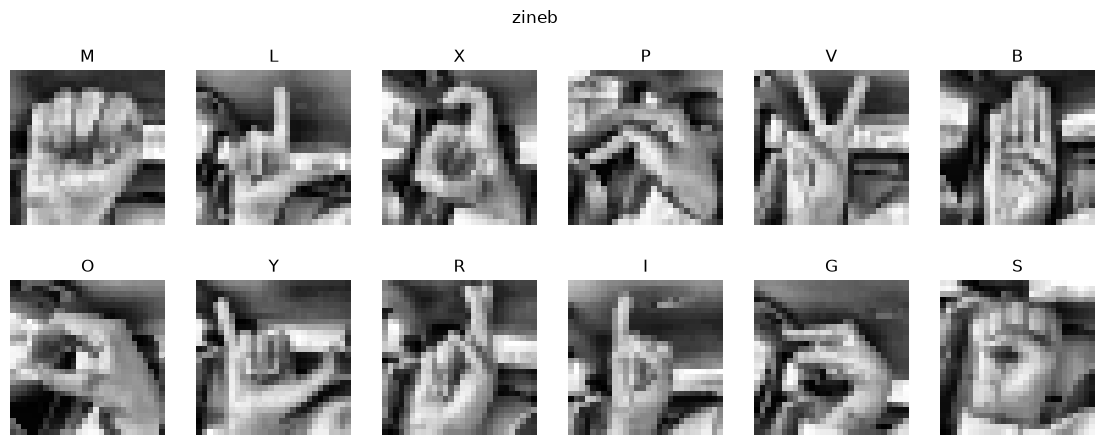

In [3]:
import matplotlib.pyplot as plt

for person in df["person"].unique():
    sub = df[df["person"] == person].sample(min(12, (df["person"] == person).sum()), random_state=0)
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (i, r) in zip(axes.ravel(), sub.iterrows()):
        ax.imshow(X[i].squeeze(), cmap="gray")
        ax.set_title(r["letter"])
    plt.suptitle(person)
    plt.show()

In [ ]:
import os, json, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from src.preprocess import preprocess_image

model = keras.models.load_model("../data/cnn_final.keras")

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letter_to_idx = {v: k for k, v in idx_to_letter.items()}
letters = [idx_to_letter[i] for i in range(24)]

paths = []
for ext in ("jpg", "jpeg", "JPG", "JPEG", "png", "PNG"):
    paths += glob.glob(f"../data/real/*/*/*.{ext}")
paths = sorted(set(paths))

rows, X, skipped = [], [], []
for path in paths:
    parts = path.replace("\\", "/").split("/")
    person, letter = parts[-3], parts[-2].upper()
    if letter not in letter_to_idx:
        continue
    img = cv2.imread(path)
    if img is None:
        skipped.append(path)
        continue
    X.append(preprocess_image(img))
    rows.append({"person": person, "letter": letter,
                 "y": letter_to_idx[letter], "path": path})

X = np.array(X)
df = pd.DataFrame(rows)
print(len(df), "images chargées ;", len(skipped), "illisibles")
print(skipped)
print(df.groupby(["person", "letter"]).size().unstack(fill_value=0))

152 images chargées ; 0 illisibles
[]
letter  A  B  C  D  E  F  G  H  I  K  ...  P  Q  R  S  T  U  V  W  X  Y
person                                ...                              
malak   4  4  5  5  5  5  4  4  4  5  ...  4  5  5  5  5  5  5  5  5  5
sara    0  0  0  0  0  0  1  1  1  1  ...  1  1  1  1  1  1  1  1  1  1
zineb   1  1  1  1  1  1  1  1  1  1  ...  1  1  1  1  1  1  1  1  1  1

[3 rows x 24 columns]


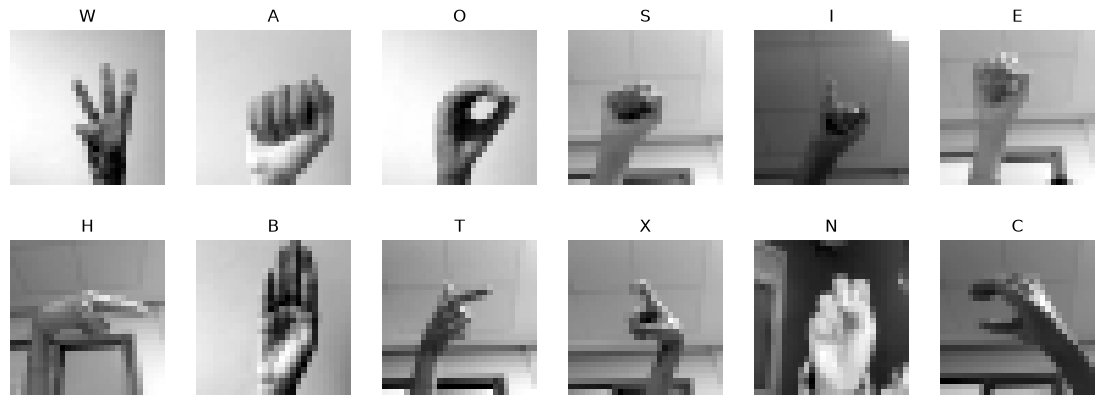

In [ ]:
n_show = min(12, len(X))
idxs = np.random.default_rng(0).choice(len(X), n_show, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), idxs):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(df.loc[i, "letter"])
plt.show()

In [ ]:
proba = model.predict(X, verbose=0)
df["pred"] = proba.argmax(axis=1)
df["conf"] = proba.max(axis=1)
df["ok"] = df["pred"] == df["y"]

print(f"Accuracy sur photos réelles : {df['ok'].mean():.3f}")
print(f"F1 macro : {f1_score(df['y'], df['pred'], average='macro'):.3f}")

print("\nAccuracy par personne :")
print(df.groupby("person")["ok"].mean().round(3))

print("\nAccuracy par lettre (les plus faibles) :")
print(df.assign(letter=df["letter"]).groupby("letter")["ok"].mean().sort_values().head(8).round(3))

Accuracy sur photos réelles : 0.266
F1 macro : 0.268

Accuracy par personne :
person
malak    0.273
sara     0.222
Name: ok, dtype: float64

Accuracy par lettre (les plus faibles) :
letter
C    0.000
E    0.000
G    0.000
I    0.000
M    0.000
S    0.000
X    0.000
T    0.167
Name: ok, dtype: float64


In [ ]:
print(df.groupby("ok")["conf"].describe().round(3))

       count   mean    std    min    25%    50%    75%  max
ok                                                         
False   94.0  0.677  0.212  0.256  0.523  0.667  0.876  1.0
True    34.0  0.846  0.198  0.363  0.756  0.955  0.992  1.0


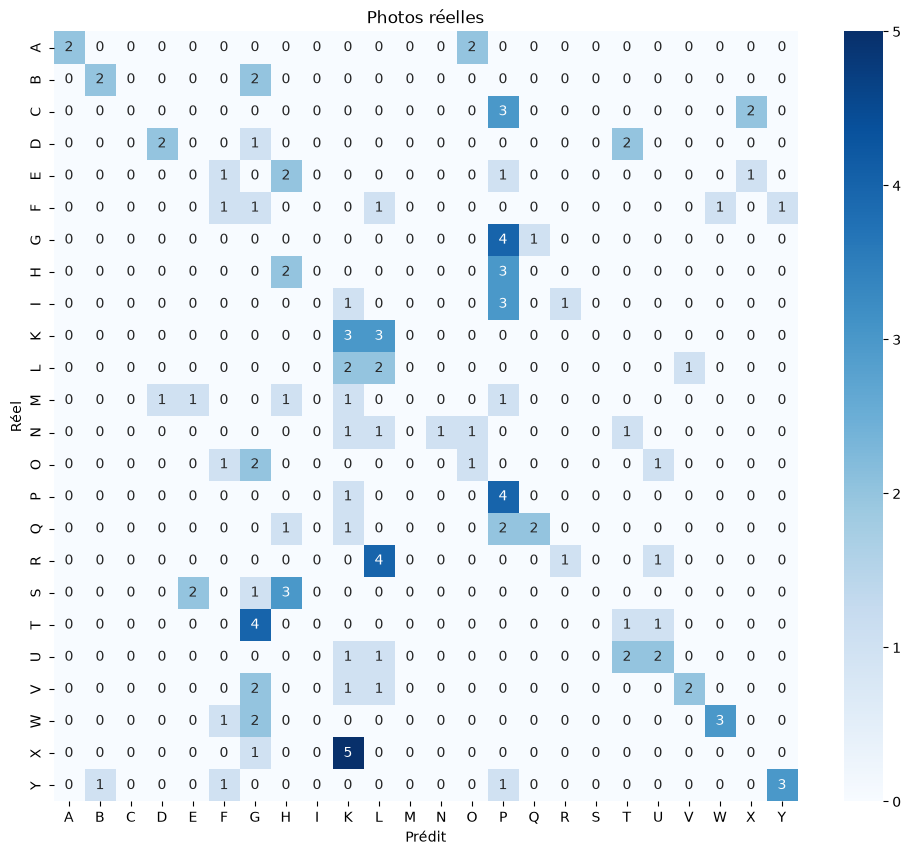

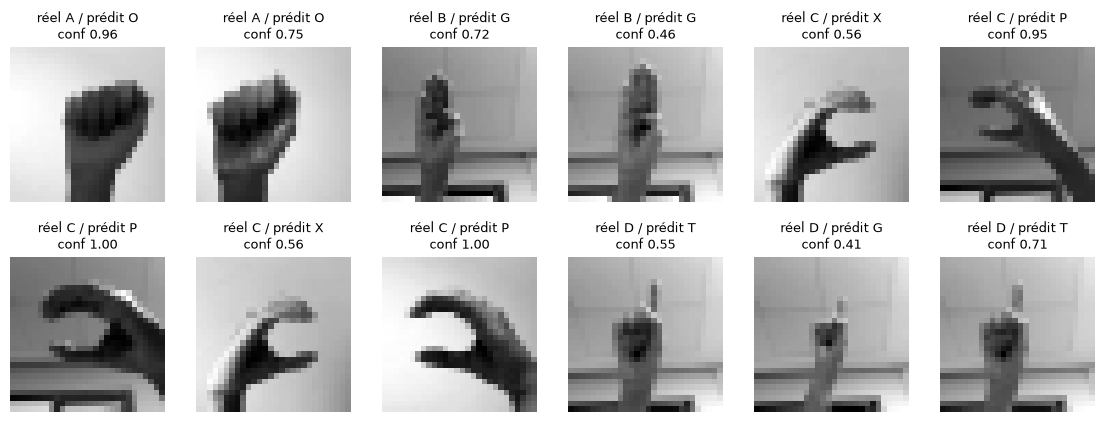

In [ ]:
cm = confusion_matrix(df["y"], df["pred"], labels=range(24))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=letters, yticklabels=letters)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Photos réelles")
plt.show()

wrong = df[~df["ok"]].head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, (i, r) in zip(axes.ravel(), wrong.iterrows()):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(f"réel {idx_to_letter[r['y']]} / prédit {idx_to_letter[r['pred']]}\nconf {r['conf']:.2f}", fontsize=9)
    ax.axis("off")
plt.show()

In [ ]:
real_results = {
    "n_images": int(len(df)),
    "n_persons": int(df["person"].nunique()),
    "accuracy": float(df["ok"].mean()),
    "f1_macro": float(f1_score(df["y"], df["pred"], average="macro")),
    "accuracy_by_person": df.groupby("person")["ok"].mean().round(4).to_dict(),
}
with open("../docs/real_results.json", "w") as f:
    json.dump(real_results, f, indent=2)

In [ ]:
def center_crop_zoom(img, zoom=0.7):
    h, w = img.shape[:2]
    s = int(min(h, w) * zoom)
    y0, x0 = (h - s) // 2, (w - s) // 2
    return img[y0:y0 + s, x0:x0 + s]

def prep_equalize(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.equalizeHist(g)
    return preprocess_image(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR))

variants = {
    "normal": preprocess_image,
    "flip horizontal": lambda im: preprocess_image(cv2.flip(im, 1)),
    "zoom 70 %": lambda im: preprocess_image(center_crop_zoom(im, 0.7)),
    "zoom 50 %": lambda im: preprocess_image(center_crop_zoom(im, 0.5)),
    "égalisation": prep_equalize,
    "flip + zoom 70 %": lambda im: preprocess_image(center_crop_zoom(cv2.flip(im, 1), 0.7)),
}

imgs = [cv2.imread(p) for p in df["path"]]
for name, fn in variants.items():
    Xv = np.array([fn(im) for im in imgs])
    pred = model.predict(Xv, verbose=0).argmax(1)
    print(f"{name:20s} accuracy = {(pred == df['y'].values).mean():.3f}")
    

normal               accuracy = 0.458
flip horizontal      accuracy = 0.229
zoom 70 %            accuracy = 0.438
zoom 50 %            accuracy = 0.229
égalisation          accuracy = 0.458
flip + zoom 70 %     accuracy = 0.229


In [4]:
import cv2
from src.predict import predict
print(predict(cv2.imread("C:\\Users\\Malak\\OneDrive\\Documents\\S2_EMSI\\DM\\projet_sign_language\\Projet\\data\\real\\malak\\A\\01.jpeg")))

('A', 0.9994215965270996, True)
